# Figures

## Load simulation data

In [56]:
include("packages.jl")

filename = "output/sol_2025-11-19_14-39.jld2"

@load filename sol local_tags_list

┌ Warning: some parameters could not be resolved for type OrdinaryDiffEqCore.InterpolationData{ODEFunction{true, SciMLBase.FullSpecialize, typeof(ODE_parallel_distributed!), Matrix{Float64}, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, typeof(SciMLBase.DEFAULT_OBSERVED), Nothing, Nothing, Nothing, Nothing},Vector{Vector{Float64}},Vector{Float64},Vector{Vector{Vector{Float64}}},Nothing,OrdinaryDiffEqBDF.FBDFCache{5,OrdinaryDiffEqNonlinearSolve.NLSolver{NLNewton{Rational{Int64}, Rational{Int64}, Rational{Int64}, Nothing},true,Vector{Float64},Rational{Int64},Nothing,Float64,OrdinaryDiffEqNonlinearSolve.NLNewtonCache{Vector{Float64},Float64,Float64,Vector{Float64},Matrix{Float64},Matrix{Float64},SciMLBase.UJacobianWrapper{true, ODEFunction{true, SciMLBase.FullSpecialize, typeof(ODE_parallel_distributed!), Matrix{Float64}, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, Nothing, typeof(SciMLBase.

2-element Vector{Symbol}:
 :sol
 :local_tags_list

## Data preparation

In [3]:
df_list = sequence_dataframes(sol, local_tags_list); # Divide sequences in a list of dataframes that have the metabolites for all and the ribosomes for one sequence
sequences = Dict(x => i for (i, x) in enumerate(local_tags_list[1].seq_names)) # Dictionary that connects the index with the name of a sequence in local_tags_list
println("Sequences in data set:")
for i in eachindex(local_tags_list[1].seq_names)
    println(local_tags_list[1].seq_names[i])
end

Sequences in data set:
rplE
Eco_lacS


## Translation elongation rate profile

In [2]:
default(
	linewidth 	= 3,
	guidefont 	= font(26),
	tickfont 	= font(18),
	legendfont	= font(18)
	)

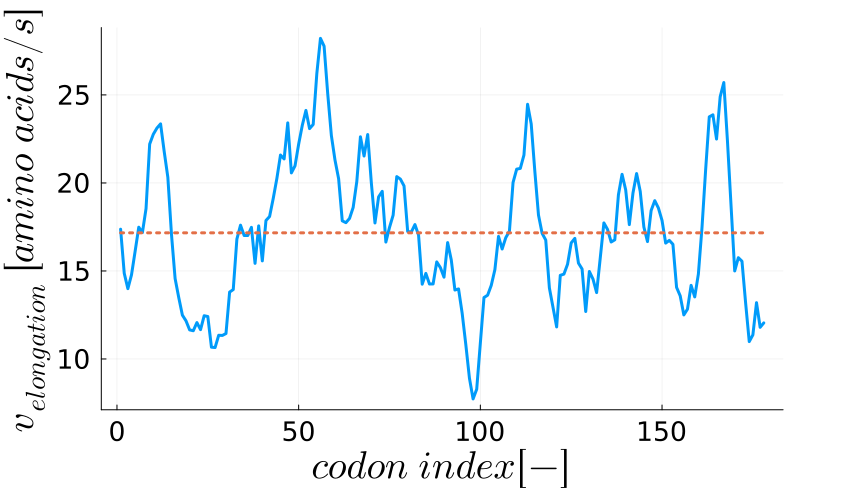

In [4]:
# Function input
sequence_name    = "rplE"
idx         = sequences[sequence_name]
tags        = local_tags_list[idx]
y           = df_list[idx][end,2:end] |> collect;
c_RIB       = y[tags.idx_first_codon:end];

# Calculation
V_TL_EL         = calculate_V_TL_EL(tags, y);
V_EL_smooth, h1 = V_TL_EL_smooth(tags, V_TL_EL, c_RIB)

# Plotting
plot(V_EL_smooth, xlabel = L"codon\ index [-]", 
	ylabel = L"v_{elongation}\ [amino\ acids/s]",
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)
plot!(h1, linestyle =:dot, label = false)

## Time courses of state variables

In [5]:
sequence_name    = "rplE"
idx         = sequences[sequence_name]

variable  = :PRT

t           = df_list[idx].time
metabolite  = df_list[idx][!,variable];

In [24]:
default(
	linewidth 	= 3,
	guidefont 	= font(18),
	tickfont 	= font(18),
	legendfont	= font(8)
	)

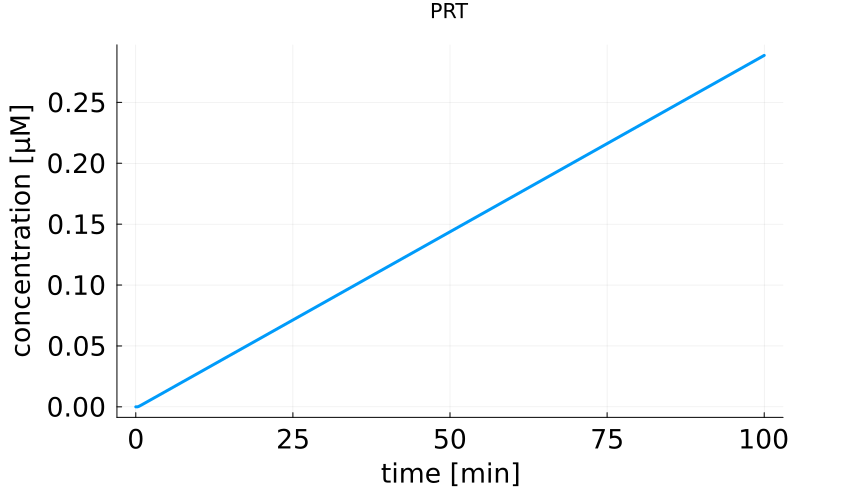

In [55]:
# Plotting
plot(t, metabolite, xlabel = "time [min]", 
	ylabel = "concentration [µM]", title = String(variable),
	size = (850, 500), left_margin = 5mm, bottom_margin = 7mm, top_margin = 5mm, right_margin = 15mm,
	legend=:topright, legendfontsize = 18, label = false)

#### Save figure

In [ ]:
foldername 	= joinpath(pwd(),"output" ,"plots") 
filename 	= String(variable)
filepath = joinpath(foldername, filename)
savefig(filepath)

"c:\\Users\\cedri\\TXTLv2\\src\\output\\plots"

## Translation rate

In [54]:
translation_rate = calculate_translation_rate(df_list[idx])

0.0028968554919308496